# Baseline Edge AI Challenge 2026
Detection (CNN grid 15x20) + intent (TextCNN), dùng chung 1 thư mục data.
Mỗi phần export int8 `.tflite` + `.cc/.h` → copy vào `esp32s3_infer_script/main/models/`.


In [1]:
!gdown --id 1mV7_CsoWpL-4K4sHNoasbgQELobh-Hms

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1mV7_CsoWpL-4K4sHNoasbgQELobh-Hms
From (redirected): https://drive.google.com/uc?id=1mV7_CsoWpL-4K4sHNoasbgQELobh-Hms&confirm=t&uuid=645580df-9150-4ed0-b82c-7de77aa9d8c9
To: /content/kaggle_data.zip
100% 855M/855M [00:09<00:00, 87.8MB/s]


In [2]:
!unzip kaggle_data.zip -d egde-ai-challenge-2026-lan-2-qualifiers

Streaming output truncated to the last 5000 lines.
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/06778.txt  
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/08932.txt  
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/00822.txt  
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/02325.txt  
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/05774.txt  
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/05118.txt  
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/03224.txt  
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/07553.txt  
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/06807.txt  
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/08442.txt  
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/04175.txt  
  inflating: egde-ai-challenge-2026-lan-2-qualifiers/train/labels/07845.txt  
  inflating: 

In [3]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 42.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


## 1. Detection


In [4]:
# 1. load data & thong ke class
import glob
from collections import Counter

data = "egde-ai-challenge-2026-lan-2-qualifiers"
classes = open(f"{data}/classes.txt").read().split()

cnt = Counter()
for f in glob.glob(f"{data}/train/labels/*.txt"):
    for l in open(f):
        cnt[int(l.split()[0])] += 1

print("So luong moi class:", {classes[k]: v for k, v in sorted(cnt.items())})
# nx: cac class deu nhau (~5k-5.7k), data rat can bang

So luong moi class: {'bottle': 5798, 'cup': 5707, 'phone': 5728, 'book': 5199, 'mouse': 5510, 'box': 5121, 'toy_car': 5711}


In [5]:
# 2. dataloader
import glob, os, cv2, torch
from torch.utils.data import Dataset, DataLoader

class DetData(Dataset):
    def __init__(self, imgs):
        self.imgs = imgs
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        p = self.imgs[i]
        im = cv2.imread(p)[:, :, ::-1] / 255.0 # doc bgr -> rgb, norm 0-1
        im = torch.tensor(im, dtype=torch.float32).permute(2, 0, 1)

        # grid 15x20: [obj, tx, ty, w, h, cls]
        # dung offset tx, ty trong cell de cnn nho hoc de hon
        tgt = torch.zeros(6, 15, 20)
        lp = p.replace("/images/", "/labels/").replace(".png", ".txt")
        if os.path.exists(lp):
            for l in open(lp):
                c, x, y, w, h = map(float, l.split())
                gx = min(int(x * 20), 19)
                gy = min(int(y * 15), 14)
                tx = x * 20 - gx # offset trong cell [0, 1]
                ty = y * 15 - gy # offset trong cell [0, 1]
                tgt[:, gy, gx] = torch.tensor([1.0, tx, ty, w, h, c])
        return im, tgt

imgs = sorted(glob.glob(f"{data}/train/images/*.png"))
train_loader = DataLoader(DetData(imgs[:5000]), batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(DetData(imgs[5000:]), batch_size=32)
print("train:", len(train_loader.dataset), "val:", len(val_loader.dataset))

train: 5000 val: 1000


In [6]:
# 3. model
import torch.nn as nn

backbone = nn.Sequential(
    nn.Conv2d(3, 16, 3, 1, 1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 24, 3, 1, 1), nn.BatchNorm2d(24), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(24, 36, 3, 1, 1), nn.BatchNorm2d(36), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(36, 36, 3, 1, 1), nn.BatchNorm2d(36), nn.ReLU(), nn.MaxPool2d(2)
)

head = nn.Sequential(
    nn.Conv2d(36, 28, 3, 1, 1), nn.BatchNorm2d(28), nn.ReLU(),
    nn.Conv2d(28, 12, 1)
)

nn.init.constant_(head[3].bias[3:5], -2.0)
nn.init.constant_(head[3].bias[0], -2.0)

model = nn.Sequential(backbone, head)
print("backbone:", sum(p.numel() for p in backbone.parameters()))
print("head    :", sum(p.numel() for p in head.parameters()))
print("total   :", sum(p.numel() for p in model.parameters()))

backbone: 23664
head    : 9504
total   : 33168


In [7]:
# 4. train
from tqdm import tqdm
import torch
import torch.nn.functional as F
from torchvision.ops import box_iou, batched_nms, generalized_box_iou_loss
from torchmetrics.detection import MeanAveragePrecision

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
epochs, patience = 1,5
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-5)
gy, gx = (grid.to(device) for grid in torch.meshgrid(torch.arange(15), torch.arange(20), indexing="ij"))

def decode_boxes(bx):
    cx = ((bx[0] if bx.dim() == 3 else bx[:, 0]) + gx) / 20
    cy = ((bx[1] if bx.dim() == 3 else bx[:, 1]) + gy) / 15
    w, h = (bx[2], bx[3]) if bx.dim() == 3 else (bx[:, 2], bx[:, 3])
    return torch.stack([(cx - w/2).clamp(0, 1), (cy - h/2).clamp(0, 1),
                        (cx + w/2).clamp(0, 1), (cy + h/2).clamp(0, 1)], dim=-1)

def evaluate(conf_th=0.3):
    model.eval()
    metric = MeanAveragePrecision(iou_type="bbox")
    metric.warn_on_many_detections = False
    ious_list = []
    tp_cnt, fp_cnt, gt_cnt = 0, 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            out = model(x.to(device))
            for pred, target in zip(out, y.to(device)):
                gm = target[0] == 1
                gt_b = decode_boxes(target[1:5])[gm]
                gt_c = target[5][gm].long()
                gt_cnt += len(gt_b)
                if len(gt_b):
                    ious_list.extend(box_iou(decode_boxes(pred[1:5].sigmoid())[gm], gt_b).diag().tolist())

                boxes = decode_boxes(pred[1:5].sigmoid()).reshape(-1, 4)
                prob, labels = pred[5:].softmax(dim=0).max(dim=0)
                scores = (pred[0].sigmoid() * prob).flatten()
                labels = labels.flatten()
                mask = scores > 0.05
                boxes, scores, labels = boxes[mask], scores[mask], labels[mask]
                if len(boxes):
                    keep = batched_nms(boxes, scores, labels, 0.5)
                    boxes, scores, labels = boxes[keep], scores[keep], labels[keep]
                metric.update([{'boxes': boxes.cpu(), 'scores': scores.cpu(), 'labels': labels.cpu()}],
                              [{'boxes': gt_b.cpu(), 'labels': gt_c.cpu()}])

                mask = scores >= conf_th
                pb, ps, pc = boxes[mask], scores[mask], labels[mask]
                if not len(pb):
                    continue
                if not len(gt_b):
                    fp_cnt += len(pb)
                    continue
                ious = box_iou(pb, gt_b)
                used = torch.zeros(len(gt_b), dtype=torch.bool, device=device)
                for i in ps.argsort(descending=True):
                    row = ious[i].clone()
                    row[(gt_c != pc[i]) | used] = -1
                    best_iou, gi = row.max(dim=0)
                    if best_iou >= 0.5:
                        tp_cnt += 1
                        used[gi] = True
                    else:
                        fp_cnt += 1
    p = tp_cnt / (tp_cnt + fp_cnt + 1e-6)
    r = tp_cnt / (gt_cnt + 1e-6)
    res = metric.compute()
    print(f"TP={tp_cnt} FP={fp_cnt} GT={gt_cnt}")
    return (sum(ious_list) / (len(ious_list) + 1e-6), res['map_50'].item(),
            res['map'].item(), 2 * p * r / (p + r + 1e-6))

best_map, bad_epochs = 0.0, 0
for ep in range(epochs):
    model.train()
    pbar = tqdm(train_loader, desc=f"Epoch {ep+1}/{epochs}")
    for x, y in pbar:
        x, y = x.to(device), y.to(device)
        out = model(x)
        m = y[:, 0] == 1
        bce = F.binary_cross_entropy_with_logits(out[:, 0], y[:, 0], reduction="none")
        l_obj = (bce[m].sum() + 0.5 * bce[~m].sum()) / max(m.sum().item(), 1.0)
        box, target = out[:, 1:5].sigmoid(), y[:, 1:5]
        loss = (l_obj
                + 5.0 * generalized_box_iou_loss(decode_boxes(box)[m], decode_boxes(target)[m], reduction="mean")
                + 2.0 * F.l1_loss(box.permute(0, 2, 3, 1)[m], target.permute(0, 2, 3, 1)[m])
                + F.cross_entropy(out[:, 5:].permute(0, 2, 3, 1)[m], y[:, 5].long()[m]))
        opt.zero_grad()
        loss.backward()
        opt.step()
        pbar.set_postfix({"loss": f"{loss.item():.4f}"})
    scheduler.step()
    iou_val, map50_val, map50_95_val, f1_val = evaluate()
    print(f"[Val] IoU: {iou_val:.4f} | mAP@50: {map50_val:.4f} | mAP50-95: {map50_95_val:.4f} | F1: {f1_val:.4f}")
    if map50_val > best_map:
        best_map, bad_epochs = map50_val, 0
        torch.save(model.state_dict(), "best_model.pth")
        print(f"-> Luu best_model.pth (best mAP@50: {best_map:.4f})")
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print(f"-> Early stopping tai epoch {ep+1}!")
            break


Epoch 1/1: 100%|██████████| 157/157 [00:28<00:00,  5.51it/s, loss=5.4988]


TP=1213 FP=860 GT=6232
[Val] IoU: 0.5838 | mAP@50: 0.2561 | mAP50-95: 0.0775 | F1: 0.2921
-> Luu best_model.pth (best mAP@50: 0.2561)


In [8]:
!pip install -q onnx2tf onnx onnxslim

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.35.1 which is incompatible.


In [9]:
import numpy as np
import tensorflow as tf
import onnx2tf.onnx2tf as otf

model.cpu().eval().load_state_dict(torch.load("best_model.pth", map_location="cpu", weights_only=True))
torch.onnx.export(model, torch.randn(1, 3, 240, 320), "model.onnx", input_names=["input"], output_names=["output"])
otf.download_test_image_data = lambda: np.zeros((20, 128, 128, 3), dtype=np.float32)

otf.convert(
    "model.onnx",
    output_folder_path="saved_model",
    not_use_onnxsim=True,
    non_verbose=True,
    tflite_backend="tf_converter",
)

import os
assert os.path.exists("saved_model/saved_model.pb"), os.listdir("saved_model")

def rep_data():
    for i in range(100):
        x = val_loader.dataset[i][0].permute(1, 2, 0).unsqueeze(0).numpy().astype(np.float32)
        yield [x]

converter = tf.lite.TFLiteConverter.from_saved_model("saved_model")
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = rep_data
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = converter.inference_output_type = tf.int8
tflite_model = converter.convert()
open("model_int8.tflite", "wb").write(tflite_model)
print("Quantized:", len(tflite_model), "bytes")

cc_dir = "."
def to_cc(data, name):
    rows = ",\n".join("  " + ", ".join(f"0x{b:02x}" for b in data[i:i + 16]) for i in range(0, len(data), 16))
    open(f"{cc_dir}/{name}.h", "w").write(f"#pragma once\nextern const unsigned char {name}[];\nextern const unsigned int {name}_len;\n")
    open(f"{cc_dir}/{name}.cc", "w").write(f'#include "{name}.h"\nalignas(16) const unsigned char {name}[] = {{\n{rows}\n}};\nconst unsigned int {name}_len = {len(data)};\n')
    print(f"Saved {name}.cc/.h ({len(data)} bytes)")
to_cc(tflite_model, "det_model")

[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
Applied 5 of general pattern rewrite rules.
[torch.onnx] Optimize the ONNX graph... ✅
Quantized: 42208 bytes
Saved det_model.cc/.h (42208 bytes)


In [10]:
import numpy as np
from ai_edge_litert.interpreter import Interpreter

interp = Interpreter(model_path="model_int8.tflite")
interp.allocate_tensors()
inp, output = interp.get_input_details()[0], interp.get_output_details()[0]
img_path = imgs[5000]
im = cv2.imread(img_path)[:, :, ::-1] / 255.0
scale, zero = inp["quantization"]
im_q = np.clip(np.round(im[None] / scale + zero), -128, 127).astype(np.int8)
interp.set_tensor(inp["index"], im_q)
interp.invoke()
scale, zero = output["quantization"]
pred = torch.from_numpy((interp.get_tensor(output["index"])[0].astype(np.float32) - zero) * scale).permute(2, 0, 1).to(device)
prob, cls_ids = pred[5:].softmax(0).max(0)
scores = (pred[0].sigmoid() * prob).flatten()
boxes, cls_ids = decode_boxes(pred[1:5].sigmoid()).reshape(-1, 4), cls_ids.flatten()
mask = scores >= 0.3
b, s, c = boxes[mask], scores[mask], cls_ids[mask]
if len(b):
    keep = batched_nms(b, s, c, 0.5)
    b, s, c = b[keep], s[keep], c[keep]
print(f"Detections: {len(b)}")
for box, score, label in zip(b, s, c):
    print(f"{classes[label]}: conf={score:.3f}, box={[round(v, 3) for v in box.tolist()]}")

Detections: 2
phone: conf=0.335, box=[0.162, 0.208, 0.311, 0.297]
bottle: conf=0.325, box=[0.125, 0.34, 0.214, 0.505]


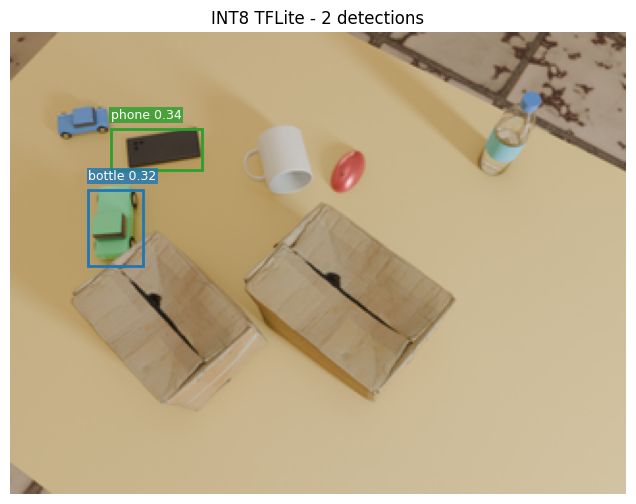

In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

H, W = im.shape[:2]
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(im)  # im đã là RGB, giá trị 0..1

cmap = plt.get_cmap("tab10")
for box, score, label in zip(b, s, c):
    x1, y1, x2, y2 = box.tolist()
    # box đang ở dạng chuẩn hóa 0..1 -> đổi sang pixel
    x1, x2 = x1 * W, x2 * W
    y1, y2 = y1 * H, y2 * H
    color = cmap(int(label) % 10)
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                   linewidth=2, edgecolor=color, facecolor="none"))
    ax.text(x1, max(y1 - 4, 0), f"{classes[label]} {score:.2f}",
            color="white", fontsize=9, va="bottom",
            bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"))

ax.set_title(f"INT8 TFLite - {len(b)} detections")
ax.axis("off")
plt.show()

## 2. Intent (TextCNN)


In [12]:
import re, pandas as pd, torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

df = pd.read_csv(f"{data}/intent_train.csv")
torch.manual_seed(42)
order = torch.randperm(len(df)).tolist()
train, val = df.iloc[order[:4800]], df.iloc[order[4800:]]
tokens = lambda text: re.findall(r"\w+", text.lower())
vocab = {word: i + 2 for i, word in enumerate(sorted({w for q in train.question for w in tokens(q)}))}
labels = sorted(df.intent.unique().tolist())
label_ids = {name: i for i, name in enumerate(labels)}
def encode(texts):
    ids = [[vocab.get(w, 1) for w in tokens(text)] for text in texts]
    return torch.tensor([(row + [0] * 32)[:32] for row in ids], dtype=torch.long)
train_loader = DataLoader(TensorDataset(encode(train.question), torch.tensor([label_ids[y] for y in train.intent])), batch_size=64, shuffle=True)
val_x, val_y = encode(val.question), torch.tensor([label_ids[y] for y in val.intent])
print(len(vocab), len(labels), len(train), len(val))

261 5 4800 1200


In [13]:
class TextCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab) + 2, 32, padding_idx=0)
        self.conv = nn.Conv1d(32, 32, 3, padding=1)
        self.fc = nn.Linear(32, len(labels))

    def forward(self, x):
        features = self.conv(self.embedding(x).transpose(1, 2)).relu()
        return self.fc(features.amax(dim=-1))

device = "cuda" if torch.cuda.is_available() else "cpu"
model = TextCNN().to(device)
print(sum(p.numel() for p in model.parameters()), "parameters")

11685 parameters


In [14]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
best = 0
for epoch in range(10):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = nn.functional.cross_entropy(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
    model.eval()
    with torch.no_grad():
        accuracy = (model(val_x.to(device)).argmax(1).cpu() == val_y).float().mean().item()
    print(f"Epoch {epoch + 1}: val accuracy {accuracy:.3f}")
    if accuracy > best:
        best = accuracy
        torch.save({"model": model.state_dict(), "vocab": vocab, "labels": labels}, "best_textcnn.pth")

Epoch 1: val accuracy 0.852
Epoch 2: val accuracy 0.926
Epoch 3: val accuracy 0.972
Epoch 4: val accuracy 0.983
Epoch 5: val accuracy 0.990
Epoch 6: val accuracy 0.992
Epoch 7: val accuracy 0.995
Epoch 8: val accuracy 0.998
Epoch 9: val accuracy 0.999
Epoch 10: val accuracy 0.999


In [15]:
model.load_state_dict(torch.load("best_textcnn.pth", map_location=device, weights_only=True)["model"])
model.eval()
test = pd.read_csv(f"{data}/intent_test.csv")
with torch.no_grad():
    pred = torch.cat([model(x.to(device)).argmax(1).cpu() for x in DataLoader(encode(test.question), batch_size=256)])
test.assign(intent=[labels[i] for i in pred.tolist()]).head()

,question_id,question,intent
0,q_0001,Trong buc anh nay co bao nhieu nhom mon do kha...,LIST
1,q_0002,"Cho minh hoi, trong anh co xuat hien tach khong?",EXIST
2,q_0003,Xin dem so thung giay trong hinh anh.,COUNT
3,q_0004,Ban co biet mat ban duoc lam bang go hay nhua ...,OUT_OF_SCOPE
4,q_0005,"Xin hoi, cai remote nam o dau trong canh?",OUT_OF_SCOPE


In [16]:
import os, numpy as np, tensorflow as tf
from ai_edge_litert.interpreter import Interpreter

# 1) Dựng lại model bằng Keras, chép trọng số từ PyTorch
sd = {k: v.detach().cpu().numpy() for k, v in model.cpu().eval().state_dict().items()}
V, E = sd["embedding.weight"].shape
C = sd["conv.weight"].shape[0]
n_cls = sd["fc.weight"].shape[0]

inp_k = tf.keras.Input(shape=(32,), batch_size=1, dtype=tf.int32, name="tokens")
x = tf.keras.layers.Embedding(V, E, name="emb")(inp_k)
x = tf.keras.layers.Conv1D(C, 3, padding="same", activation="relu", name="conv")(x)
x = tf.keras.layers.GlobalMaxPooling1D(name="gmp")(x)
logits = tf.keras.layers.Dense(n_cls, name="fc")(x)
km = tf.keras.Model(inp_k, logits)

km.get_layer("emb").set_weights([sd["embedding.weight"]])
km.get_layer("conv").set_weights([sd["conv.weight"].transpose(2, 1, 0), sd["conv.bias"]])  # [out,in,k] -> [k,in,out]
km.get_layer("fc").set_weights([sd["fc.weight"].T, sd["fc.bias"]])                         # [out,in] -> [in,out]

# 2) Kiểm tra Keras khớp PyTorch (phải sai số ~1e-5)
X = val_x[:200].numpy().astype(np.int32)
with torch.no_grad():
    pt = model(torch.from_numpy(X).long()).numpy()
kr = np.concatenate([km(X[i:i+1], training=False).numpy() for i in range(200)])
print("Keras vs torch max|diff|:", np.abs(kr - pt).max(), "| argmax khớp:", (kr.argmax(1) == pt.argmax(1)).mean())

# 3) INT8 (input giữ int32, output int8), calibrate bằng mẫu xáo trộn
rng = np.random.default_rng(0)
idx = rng.permutation(len(val_x))[:500]
def rep_data():
    for i in idx:
        yield [val_x[int(i):int(i)+1].numpy().astype(np.int32)]

converter = tf.lite.TFLiteConverter.from_keras_model(km)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = rep_data
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_output_type = tf.int8
open("textcnn_int8.tflite", "wb").write(converter.convert())

# 4) Liệt kê op (để đăng ký trong firmware) + đo accuracy INT8
tf.lite.experimental.Analyzer.analyze(model_path="textcnn_int8.tflite")
interp = Interpreter(model_path="textcnn_int8.tflite"); interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
q = 0
for i in range(len(val_x)):
    interp.set_tensor(inp["index"], val_x[i:i+1].numpy().astype(np.int32)); interp.invoke()
    q += int(interp.get_tensor(out["index"])[0].argmax()) == int(val_y[i])
print("INT8 acc:", q / len(val_x))

tflite_model = open("textcnn_int8.tflite", "rb").read()
print(len(tflite_model), "bytes")
to_cc(tflite_model, "textcnn_model")

Keras vs torch max|diff|: 2.3245811e-06 | argmax khớp: 1.0
=== textcnn_int8.tflite ===

Your TFLite model has '1' subgraph(s). In the subgraph description below,
T# represents the Tensor numbers. For example, in Subgraph#0, the GATHER op takes
tensor #8 and tensor #0 as input and produces tensor #9 as output.

Subgraph#0 main(T#0) -> [T#14]
  Op#0 GATHER(T#8, T#0) -> [T#9]
  Op#1 RESHAPE(T#9, T#1[1, 1, 32, 32]) -> [T#10]
  Op#2 CONV_2D(T#10, T#7, T#6[2374, 102, -297, -274, -596, ...]) -> [T#11]
  Op#3 RESHAPE(T#11, T#2[1, 32, 32]) -> [T#12]
  Op#4 REDUCE_MAX(T#12, T#3[1]) -> [T#13]
  Op#5 FULLY_CONNECTED(T#13, T#5, T#4[-710, 727, -265, -279, 13]) -> [T#14]

Tensors of Subgraph#0
  T#0(serving_default_tokens:0) shape:[1, 32], type:INT32
  T#1(model_1/conv/Conv1D/ExpandDims) shape:[4], type:INT32 RO 16 bytes, buffer: 2, data:[1, 1, 32, 32]
  T#2(model_1/conv/Conv1D/Squeeze) shape:[3], type:INT32 RO 12 bytes, buffer: 3, data:[1, 32, 32]
  T#3(model_1/gmp/Max/reduction_indices) shape:[], t

In [17]:
import numpy as np, torch
from ai_edge_litert.interpreter import Interpreter

MAX_LEN = 32
interp = Interpreter(model_path="textcnn_int8.tflite")
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
print("input :", inp["dtype"].__name__, inp["shape"])
print("output:", out["dtype"].__name__, out["shape"], "quant(scale, zero) =", out["quantization"])

def encode(text):
    toks = text.lower().strip().split()
    ids = [vocab.get(w, 1) for w in toks][:MAX_LEN]      # 1 = unknown
    ids += [0] * (MAX_LEN - len(ids))                     # 0 = pad
    return np.array([ids], dtype=np.int32)

def softmax(x):
    e = np.exp(x - x.max())
    return e / e.sum()

def predict_tflite(text):
    interp.set_tensor(inp["index"], encode(text))
    interp.invoke()
    raw = interp.get_tensor(out["index"])[0]
    scale, zero = out["quantization"]
    logits = (raw.astype(np.float32) - zero) * scale if scale else raw.astype(np.float32)
    return softmax(logits)

@torch.no_grad()
def predict_float(text):
    x = torch.from_numpy(encode(text)).long()
    return torch.softmax(model.cpu().eval()(x)[0], dim=-1).numpy()

tests = [
    "Trong buc anh nay co bao nhieu nhom mon do khac nhau?",
    "Xin dem so thung giay trong hinh anh.",
    "Cho toi hoi, bao nhieu nhom doi tuong khac nhau xuat hien trong hinh?",
    "Co bao nhieu lop do vat co mat trong hinh?",
    "Co ly tren mat ban khong vay?",
]

print(f"\n{'câu':<38}{'TFLite int8':<26}{'Float':<26}")
agree = 0
for t in tests:
    pq, pf = predict_tflite(t), predict_float(t)
    cq, cf = int(pq.argmax()), int(pf.argmax())
    agree += cq == cf
    print(f"{t:<38}{labels[cq]:<14}{pq[cq]:.2f}      {labels[cf]:<14}{pf[cf]:.2f}")
print(f"\nKhớp float vs int8: {agree}/{len(tests)}")

input : int32 [ 1 32]
output: int8 [1 5] quant(scale, zero) = (0.07838083803653717, 4)

câu                                   TFLite int8               Float                     
Trong buc anh nay co bao nhieu nhom mon do khac nhau?LIST          1.00      LIST          1.00
Xin dem so thung giay trong hinh anh. COUNT         1.00      COUNT         1.00
Cho toi hoi, bao nhieu nhom doi tuong khac nhau xuat hien trong hinh?LIST          1.00      LIST          1.00
Co bao nhieu lop do vat co mat trong hinh?LIST          1.00      LIST          1.00
Co ly tren mat ban khong vay?         EXIST         0.99      EXIST         0.99

Khớp float vs int8: 5/5


In [18]:
correct_q = correct_f = 0
N = len(val_x)
for i in range(N):
    ids = val_x[i:i+1].numpy().astype(np.int32)
    interp.set_tensor(inp["index"], ids); interp.invoke()
    raw = interp.get_tensor(out["index"])[0].astype(np.float32)
    correct_q += int(raw.argmax()) == int(val_y[i])
    with torch.no_grad():
        correct_f += int(model(torch.from_numpy(ids).long()).argmax()) == int(val_y[i])
print(f"Float acc: {correct_f/N:.4f} | INT8 acc: {correct_q/N:.4f}")

Float acc: 0.9992 | INT8 acc: 0.9992


In [19]:
assert labels == sorted(labels), labels
print("labels:", labels)

words = sorted(vocab, key=vocab.get)
assert [vocab[w] for w in words] == list(range(2, len(words) + 2))
assert all(re.fullmatch(r"\w+", w) for w in words)

open(f"{cc_dir}/vocab.h", "w").write(
    "#pragma once\nextern const char *const vocab[];\nextern const int vocab_len;\n")
open(f"{cc_dir}/vocab.cc", "w", encoding="utf-8").write(
    '#include "vocab.h"\nconst char *const vocab[] = {\n'
    + ",\n".join(f'  "{w}"' for w in words)
    + f"\n}};\nconst int vocab_len = {len(words)};\n")
print(f"Saved vocab.cc/.h ({len(words)} từ)")

labels: ['COUNT', 'EXIST', 'LIST', 'LOCATION', 'OUT_OF_SCOPE']
Saved vocab.cc/.h (261 từ)
